# Phase 3: Historical validation against benchmarks

**Goal:** test the price-only algorithm of Phase 2 on past data, compare it with two simple benchmarks, and see how much the result depends on the settings.

**Steps:** simulate a portfolio with real trading rules → two benchmarks → checks → rolling validation → parameter sensitivity → weaknesses

**How to read this notebook**

The code is in `scripts/simulate.py` (the simulation of a portfolio) and `scripts/validation.py` (benchmarks, rolling validation, sensitivity). As in `analysis.ipynb` (Phases 1 and 2), every section first shows the **code** of a function and then runs it. The long explanation of the results is in `docs/validation.md`.

**Important:** these results are development and validation evidence, not an untouched final test. We have seen them and may use them to improve the algorithm. Only the real-time competition (Phase 5) tests it on market outcomes that nobody has seen yet.

## 0. Setup

In [1]:
import inspect
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown

# Add the scripts/ folder to the Python path (the notebook is one folder below the project root)
sys.path.insert(0, str(Path.cwd().parent / "scripts"))

import config
import portfolio
import simulate
import validation


def show_code(obj):
    # Shows the source code of a function as a code block
    return Markdown(f"```python\n{inspect.getsource(obj)}\n```")


# Chart settings: plain look, light grid lines (the same as in analysis.ipynb)
plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a897f"  # strategy, weekly benchmark, buy-and-hold benchmark
COLORS = {"Strategy": BLUE, "Equal weights, weekly": ORANGE, "Equal weights, buy and hold": GREY}

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 30

In [2]:
# Load the prices once. The Phase 2 weights use the TEFAS dates as published;
# the simulation uses the market day of every price (see section 1).
prices = portfolio.load_prices()
data = simulate.prepare()
strategy = validation.strategy_weights(prices, {})  # Phase 2 algorithm with the settings of config.py

print("Assumptions: capital", f"{config.INITIAL_CAPITAL:,}", config.REPORT_CURRENCY,
      f"| commission {config.COMMISSION:.1%} | exchange cost {config.FX_COST:.1%} on US trades")
print("Weekly decisions:", len(strategy), "from", strategy.index[0].date(), "to", strategy.index[-1].date())
print("Last day with a price: US", data["own"]["SPY"].last_valid_index().date(),
      "| Türkiye (market day)", data["own"]["DLY"].last_valid_index().date())

Assumptions: capital 10,000 TRY | commission 0.1% | exchange cost 0.2% on US trades
Weekly decisions: 219 from 2022-08-26 to 2026-10-30
Last day with a price: US 2026-11-05 | Türkiye (market day) 2026-11-04


## 1. Simulating a portfolio

A list of target weights is not yet a portfolio. To compare the strategy with benchmarks we must buy and sell the instruments the way an investor could. The rules come from the data dictionary (sections 5, 7 and 8):

- **Market day of a price.** TEFAS dates a price one business day after the market day it comes from, so the Turkish prices are moved back by one row. A US price belongs to its US trading day.
- **Exchange rate.** A US ETF is valued in lira with the first USD/TRY value dated *after* its closing day: Yahoo takes the value of a day in its first hours (London time), so that is the value closest in time to the US close.
- **Orders.** A decision uses the prices up to Friday. The orders are given on the next day on which both markets are open and filled at that day's closing price, which was not known on Friday.
- **Settlement.** Sales come first. A purchase is made only so that its payment is not due before the money of the sales has arrived.
- **Costs.** 0.1% commission on every trade and 0.2% for changing lira into dollars (or back) on every US trade. Cash earns no interest. Borrowing is not possible.

In [3]:
show_code(simulate.market_prices)

```python
def market_prices(last_day=None):
    """Reads the price of every instrument and puts it on the day of the market close it comes from.

    US ETFs: the adjusted close of the US trading day.
    Turkish funds: TEFAS dates a price one business day after the market day it comes from,
    so every price is moved back to the row before it.
    Returns a DataFrame with one row for every day on which at least one market was open,
    and NaN where the market of an instrument was closed.
    If last_day is given, only the rows of the files dated up to that day are used.
    """
    columns = {}
    for symbol in SYMBOLS:
        price = backtest.load_clean(symbol)["adj_close"].loc[:last_day]
        if config.SYMBOLS[symbol]["market"] == TURKEY:
            price = pd.Series(price.values[1:], index=price.index[:-1])  # row i comes from the day of row i-1
        columns[symbol] = price
    return pd.DataFrame(columns).sort_index()

```

In [4]:
show_code(simulate.rate_after_us_close)

```python
def rate_after_us_close(days, last_day=None):
    """USD/TRY rate for every day: the first value dated after that day.

    Yahoo takes the value of day D in the first hours of day D (London time), so the value
    dated D+1 is the first one after the US close of day D. For the last day of the data
    there is no later value yet; then the last known value is used.
    If last_day is given, only the rows of the file dated up to that day are used.
    """
    rate = backtest.load_clean(config.FX_NAME)["adj_close"].loc[:last_day]
    following = pd.Series(rate.values[1:], index=rate.index[:-1])  # the value of the next row
    following = pd.concat([following, rate.iloc[-1:]])             # the last day keeps its own value
    return following.asof(days)

```

In [5]:
show_code(simulate.order_days)

```python
def order_days(decision_days, own):
    """For every decision day: the first later day on which both markets are open.

    Returns {position of the order day in the price table: decision day}.
    Decisions without such a day in the data (the most recent one) are left out.
    """
    us_open = own.loc[:, MARKET == US].notna().any(axis=1)
    tr_open = own.loc[:, MARKET == TURKEY].notna().any(axis=1)
    both_open = own.index[us_open & tr_open]
    orders = {}
    for decision in decision_days:
        later = both_open[both_open > decision]
        if len(later) > 0:
            orders[own.index.get_loc(later[0])] = decision
    return orders

```

In [6]:
show_code(simulate.simulate)

```python
def simulate(targets, data, commission=None, fx_cost=None):
    """Simulates a portfolio that is brought to the target weights on every decision day.

    targets: one row per decision day, one column per instrument and a CASH column.
             A portfolio that is never rebalanced has only one row.
    data:    the result of prepare().
    Returns a dictionary with the daily value in lira, the value held in every
    instrument, the costs paid and the value traded.
    """
    commission = config.COMMISSION if commission is None else commission
    fx_cost = config.FX_COST if fx_cost is None else fx_cost
    fee = commission + fx_cost * (MARKET == US)  # cost of a trade, as a share of its value

    days = data["lira"].index
    price = data["lira"].to_numpy()
    is_open = data["own"].notna().to_numpy()
    orders = order_days(targets.index, data["own"])
    weights = targets[SYMBOLS].to_numpy()
    row_of = {day: row for row, day in enumerate(targets.index)}

    units = np.zeros(len(SYMBOLS))   # shares held of every instrument
    cash = float(config.INITIAL_CAPITAL)
    set_aside = 0.0                  # lira kept for purchases that are made on a later day
    planned = {}                     # day position -> list of (instrument, lira to spend)
    costs = traded = 0.0
    held, values = [], []
    first = min(orders) if orders else len(days)

    def make_purchases(t):
        """Makes the purchases planned for day t at that day's closing price; the cost is paid from the amount."""
        nonlocal costs, traded, set_aside
        for i, amount in planned.pop(t, []):
            units[i] += amount / (price[t, i] * (1 + fee[i]))
            costs += amount - amount / (1 + fee[i])
            traded += amount
            set_aside -= amount

    for t in range(first, len(days)):
        # 1) Purchases of an earlier order that are due today
        make_purchases(t)

        # 2) New orders on an order day
        if t in orders:
            assert not planned, "a purchase of the week before was not made yet"
            target = weights[row_of[orders[t]]] * (units @ price[t] + cash)
            holding = units * price[t]

            # Sales: everything above the target is sold at today's close
            sell = np.where(holding > target + TINY, holding - target, 0)
            units -= sell / price[t]
            cash += (sell * (1 - fee)).sum()
            costs += (sell * fee).sum()
            traded += sell.sum()

            # Purchases: what is below the target. If the money is not enough (the costs of
            # the sales are missing), every purchase is made smaller in the same proportion.
            buy = np.where(target > holding + TINY, target - holding, 0)
            if buy.sum() > cash:
                buy = buy * cash / buy.sum()

            # The money of the sales arrives after `wait` business days. A purchase whose
            # payment comes earlier than that is made later, on the first day its market is open.
            buy_days, sell_days = settlement_days(days[t])
            wait = sell_days[sell > 0].max() if (sell > 0).any() else 0
            for i in np.flatnonzero(buy):
                delay = max(0, wait - buy_days[i])
                start = np.busday_offset(days[t].date(), delay, roll="forward")
                later = np.flatnonzero(is_open[:, i] & (days >= pd.Timestamp(start)))
                if len(later) > 0:  # without a later price the money stays in cash
                    planned.setdefault(later[0], []).append((i, buy[i]))
                    cash -= buy[i]
                    set_aside += buy[i]

            # 3) Purchases of today's orders that do not have to wait
            make_purchases(t)

        assert cash >= -TINY, "cash is negative (borrowing)"
        held.append(units * price[t])
        values.append(units @ price[t] + cash + set_aside)

    index = days[first:]
    return {
        "value": pd.Series(values, index=index),
        "held": pd.DataFrame(held, index=index, columns=SYMBOLS),
        "usdtry": data["usdtry"].loc[index],
        "costs": costs,
        "traded": traded,
    }

```

In [7]:
show_code(simulate.metrics)

```python
def metrics(result):
    """Performance numbers of a simulated portfolio."""
    value = result["value"]
    capital = config.INITIAL_CAPITAL
    years = (value.index[-1] - value.index[0]).days / 365.25
    daily = value.pct_change().dropna()
    per_year = len(daily) / years  # days with a value per year (both calendars together)
    volatility = daily.std() * np.sqrt(per_year)
    total = value.iloc[-1] / capital - 1
    # The same portfolio counted in US dollars: the lira lost much of its value in this period
    in_usd = (value.iloc[-1] / result["usdtry"].iloc[-1]) / (capital / result["usdtry"].iloc[0]) - 1
    shares = market_shares(result)

    return {
        "start": value.index[0].strftime("%Y-%m-%d"),
        "end": value.index[-1].strftime("%Y-%m-%d"),
        "final_value": round(float(value.iloc[-1]), 2),
        "total_return_pct": round(float(total * 100), 2),
        "cagr_pct": round(float(((1 + total) ** (1 / years) - 1) * 100), 2),
        "volatility_pct": round(float(volatility * 100), 2),
        # Sharpe ratio with a risk-free rate of 0: yearly average return / yearly volatility
        "sharpe": round(float(daily.mean() * per_year / volatility), 2),
        "max_drawdown_pct": round(float((value / value.cummax() - 1).min() * 100), 2),
        "total_return_usd_pct": round(float(in_usd * 100), 2),
        "turnover_per_year": round(float(result["traded"] / value.mean() / years), 2),
        "costs": round(float(result["costs"]), 2),
        "average_share_pct": {name: round(float(shares[name].mean() * 100), 2) for name in shares.columns},
        "last_share_pct": {name: round(float(shares[name].iloc[-1] * 100), 2) for name in shares.columns},
    }

```

### 1.1 A small example that can be checked by hand

The buy-and-hold benchmark buys 1/20 of the capital (500 lira) of every instrument on the first order day. For two instruments, one from each market, we compute by hand how many shares were bought and what they were worth one week later, and compare with the simulation.

In [8]:
benchmark = validation.equal_weights(strategy.index)
hold = simulate.simulate(benchmark.iloc[:1], data)  # one row of weights: bought once, never rebalanced

first_day = hold["value"].index[0]
week_later = hold["value"].index[5]
rows = []
for symbol in ["SPY", "DLY"]:
    fee = config.COMMISSION + (config.FX_COST if config.SYMBOLS[symbol]["market"] == "United States" else 0)
    price_then = data["lira"].loc[first_day, symbol]  # price in lira on the order day
    shares = 500 / (price_then * (1 + fee))           # the cost is paid from the 500 lira
    by_hand = shares * data["lira"].loc[week_later, symbol]
    rows.append({
        "symbol": symbol,
        "price in lira on " + str(first_day.date()): price_then,
        "cost rate": fee,
        "shares bought": shares,
        "value by hand on " + str(week_later.date()): by_hand,
        "value in the simulation": hold["held"].loc[week_later, symbol],
    })
pd.DataFrame(rows).set_index("symbol").style.format("{:,.6f}")

,price in lira on 2022-08-29,cost rate,shares bought,value by hand on 2022-09-05,value in the simulation
symbol,,,,,
SPY,"6,921.403743",0.003000,0.072024,486.552664,486.552664
DLY,1.380936,0.001000,361.711549,501.029093,501.029093


## 2. Strategy against the two benchmarks

The benchmarks use the same 20 instruments, the same start, capital, currency, prices and costs:

- **Equal weights, weekly:** every instrument gets 5% on every decision day (so 50% Türkiye and 50% United States after every rebalance).
- **Equal weights, buy and hold:** 5% in every instrument on the first order day, then nothing is traded; the weights drift with the prices.

In [9]:
show_code(validation.equal_weights)

```python
def equal_weights(decision_days):
    """Benchmark weights: every instrument 1/N on every decision day, no cash."""
    weights = pd.DataFrame(1 / len(simulate.SYMBOLS), index=decision_days, columns=simulate.SYMBOLS)
    weights[portfolio.CASH] = 0.0
    return weights

```

In [10]:
show_code(validation.compare)

```python
def compare(strategy, data, start):
    """Simulates the strategy and both benchmarks from the decision day `start` on.

    The buy-and-hold benchmark gets only the first row of equal weights: it is bought
    once and never rebalanced, so its weights drift with the prices.
    """
    days = strategy.index[strategy.index >= start]
    benchmark = equal_weights(days)
    results = {
        "Strategy": simulate.simulate(strategy.loc[days], data),
        "Equal weights, weekly": simulate.simulate(benchmark, data),
        "Equal weights, buy and hold": simulate.simulate(benchmark.iloc[:1], data),
    }
    return results

```

In [11]:
whole = validation.compare(strategy, data, strategy.index[0])
summary = pd.DataFrame({name: simulate.metrics(result) for name, result in whole.items()})
rows = ["start", "end", "final_value", "total_return_pct", "cagr_pct", "volatility_pct", "sharpe",
        "max_drawdown_pct", "total_return_usd_pct", "turnover_per_year", "costs"]
summary.loc[rows]

,Strategy,"Equal weights, weekly","Equal weights, buy and hold"
start,2022-08-29,2022-08-29,2022-08-29
end,2026-11-05,2026-11-05,2026-11-05
final_value,"47,371.91","50,048.01","48,973.07"
total_return_pct,373.72,400.48,389.73
cagr_pct,45.00,46.92,46.16
volatility_pct,9.04,11.62,14.08
sharpe,4.16,3.37,2.77
max_drawdown_pct,-6.22,-9.43,-16.52
total_return_usd_pct,72.11,81.84,77.93
turnover_per_year,2.86,1.02,0.08


In [12]:
# Market allocation of every portfolio: average over all days and on the last day (percent)
shares = {}
for name, result in whole.items():
    daily = simulate.market_shares(result) * 100
    shares[(name, "average")] = daily.mean()
    shares[(name, "last day")] = daily.iloc[-1]
pd.DataFrame(shares).T

Türkiye  United States  CASH
Strategy                    average     60.48          39.20  0.32
                            last day    58.73          41.27  0.00
Equal weights, weekly       average     49.94          49.95  0.11
                            last day    50.62          49.38  0.00
Equal weights, buy and hold average     50.74          49.26  0.00
                            last day    49.07          50.93  0.00

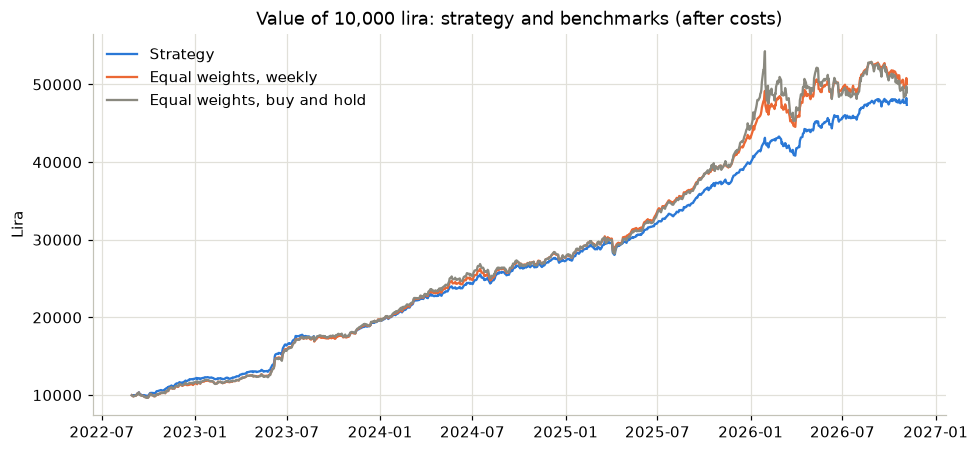

In [13]:
fig, ax = plt.subplots()
for name, result in whole.items():
    value = result["value"]
    ax.plot(value.index, value, color=COLORS[name], linewidth=1.5, label=name)
ax.set_title("Value of 10,000 lira: strategy and benchmarks (after costs)")
ax.set_ylabel("Lira")
ax.legend(loc="upper left", frameon=False)
plt.show()

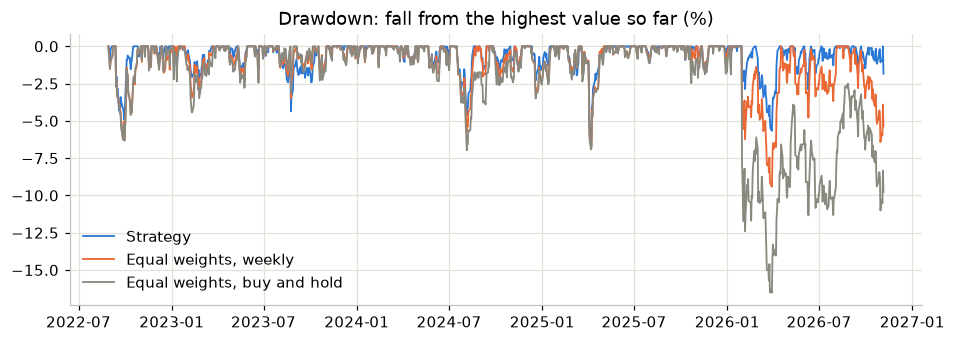

In [14]:
fig, ax = plt.subplots(figsize=(10, 3.2))
for name, result in whole.items():
    value = result["value"]
    drawdown = (value / value.cummax() - 1) * 100  # fall from the highest value so far
    ax.plot(drawdown.index, drawdown, color=COLORS[name], linewidth=1.2, label=name)
ax.set_title("Drawdown: fall from the highest value so far (%)")
ax.legend(loc="lower left", frameon=False)
plt.show()

In [15]:
# For comparison: the lira money market fund DLY alone, bought on the same day and held
dly = data["own"]["DLY"].dropna().loc[whole["Strategy"]["value"].index[0]:]
print(f"DLY alone from {dly.index[0].date()} to {dly.index[-1].date()}: {(dly.iloc[-1] / dly.iloc[0] - 1) * 100:.2f}%")
rate = data["usdtry"].loc[whole["Strategy"]["value"].index]
print(f"USD/TRY in the same period: {rate.iloc[0]:.2f} -> {rate.iloc[-1]:.2f}")

DLY alone from 2022-08-29 to 2026-11-04: 373.42%
USD/TRY in the same period: 18.18 -> 50.04


**Reading the results.** The strategy is calmer than both benchmarks (lower volatility, smaller drawdown, higher Sharpe ratio), but it did not earn more. Lira interest rates were very high in this period: the money market fund DLY alone earned about as much as the strategy. A Sharpe ratio with a risk-free rate of 0 therefore makes all three portfolios look better than they are.

## 3. Checks

`validation.py` checks its own results and stops with an error if a check fails:

- the buy-and-hold value must match a formula that can be computed by hand,
- the values must not change when the prices after a day are removed (no future data).

In [16]:
show_code(validation.check_buy_and_hold)

```python
def check_buy_and_hold(result, data):
    """Checks the simulation with a formula that can be computed by hand.

    Bought once with 1/N of the capital each (cost paid from the amount):
    value(t) = sum over i of  capital / N * price_i(t) / (price_i(start) * (1 + fee_i))
    """
    lira = data["lira"].loc[result["value"].index]
    fee = config.COMMISSION + config.FX_COST * (simulate.MARKET == simulate.US)
    by_hand = (config.INITIAL_CAPITAL / len(simulate.SYMBOLS) * lira / (lira.iloc[0] * (1 + fee))).sum(axis=1)
    difference = (by_hand - result["value"]).abs().max()
    assert difference < 1e-6, "the buy-and-hold value does not match the formula"
    return float(difference)

```

In [17]:
print("Largest difference to the formula (lira):", validation.check_buy_and_hold(whole["Equal weights, buy and hold"], data))

Largest difference to the formula (lira): 2.1827872842550278e-11


In [18]:
show_code(validation.check_no_future_data)

```python
def check_no_future_data(prices, cut="2025-06-30"):
    """Shows that the simulation does not use prices or rates that come after a day.

    Everything is computed again as if the data had been downloaded on `cut`: every price
    file and the exchange rate file end on that day. The values must be the same as with
    the full data until the day before the cut (the value of the cut day itself needs the
    exchange rate of the next day).
    """
    cut = pd.Timestamp(cut)
    short = {symbol: price.loc[:cut] for symbol, price in prices.items()}
    full = simulate.simulate(strategy_weights(prices, {}), simulate.prepare())["value"]
    part = simulate.simulate(strategy_weights(short, {}), simulate.prepare(last_day=cut))["value"]
    until = cut - pd.Timedelta(days=1)
    difference = (full.loc[:until] - part.loc[:until]).abs().max()
    assert difference < 1e-9, f"the values before {cut.date()} depend on later prices"
    return float(difference)

```

In [19]:
print("Largest difference with the data cut at 2025-06-30 (lira):", validation.check_no_future_data(prices))

Largest difference with the data cut at 2025-06-30 (lira): 0.0


## 4. Rolling validation

The decisions are used in time order, never in a random split:

1. **Training window (52 weeks):** each of 9 settings (trend windows 20/100, 50/150, 50/200 × volatility windows 21, 63, 126 days) is simulated, with the prices known before the first test decision only. The setting with the highest Sharpe ratio is chosen.
2. **Test window (26 weeks):** the chosen setting makes the decisions.
3. Move both windows forward by 26 weeks and repeat.

The test windows together form one portfolio, the *walk-forward strategy*. We compare it with the fixed setting of `config.py` and the two benchmarks over the same weeks.

In [20]:
print("Settings tried:")
for settings in validation.GRID:
    print("  ", validation.label(settings))

Settings tried:
   SMA 20/100, vol 21 days
   SMA 20/100, vol 63 days
   SMA 20/100, vol 126 days
   SMA 50/150, vol 21 days
   SMA 50/150, vol 63 days
   SMA 50/150, vol 126 days
   SMA 50/200, vol 21 days
   SMA 50/200, vol 63 days
   SMA 50/200, vol 126 days


In [21]:
show_code(validation.use_settings)

```python
@contextmanager
def use_settings(settings):
    """Changes some values in config for a moment and puts the old values back afterwards.

    The Phase 2 functions read their settings from config, so this is how another setting is tried.
    """
    old = {name: getattr(config, name) for name in settings}
    for name, value in settings.items():
        setattr(config, name, value)
    try:
        yield
    finally:
        for name, value in old.items():
            setattr(config, name, value)

```

In [22]:
show_code(validation.walk_forward)

```python
def walk_forward(prices, data):
    """Chooses a setting on every training window and uses it on the test window after it.

    Returns (folds, weights): one row of information per step, and the weekly weights of the
    walk-forward strategy (in every test window the weights of the setting chosen for it).
    """
    by_setting = [strategy_weights(prices, settings) for settings in GRID]
    # Use only the weeks on which every setting has a decision
    weeks = by_setting[0].index
    for weights in by_setting[1:]:
        weeks = weeks.intersection(weights.index)

    folds, parts = [], []
    start = 0
    while start + TRAIN_WEEKS < len(weeks):
        train = weeks[start:start + TRAIN_WEEKS]
        test = weeks[start + TRAIN_WEEKS:start + TRAIN_WEEKS + TEST_WEEKS]

        # Training: each setting is simulated on the training weeks with the prices known
        # before the first test decision (until the day before it).
        known = simulate.prepare(last_day=test[0] - pd.Timedelta(days=1))
        sharpe = [simulate.metrics(simulate.simulate(weights.loc[train], known))["sharpe"] for weights in by_setting]
        best = max(range(len(GRID)), key=lambda k: sharpe[k])  # highest Sharpe ratio in training

        folds.append({
            "train": [train[0].strftime("%Y-%m-%d"), train[-1].strftime("%Y-%m-%d")],
            "test": [test[0].strftime("%Y-%m-%d"), test[-1].strftime("%Y-%m-%d")],
            "chosen": label(GRID[best]),
            "train_sharpe": sharpe[best],
            "default_train_sharpe": sharpe[GRID.index(DEFAULT)],
        })
        parts.append(by_setting[best].loc[test])
        start += TEST_WEEKS
    return folds, pd.concat(parts)

```

In [23]:
folds, walk_weights = validation.walk_forward(prices, data)
test_start = walk_weights.index[0]
tested = validation.compare(walk_weights, data, test_start)
tested["Strategy, fixed setting"] = simulate.simulate(strategy.loc[test_start:], data)

# Return of every portfolio in every test window
boundaries = [pd.Timestamp(fold["test"][0]) for fold in folds] + [tested["Strategy"]["value"].index[-1]]
table = []
for k, fold in enumerate(folds):
    row = {"test window": f"{fold['test'][0]} to {fold['test'][1]}", "chosen setting": fold["chosen"]}
    for name, result in tested.items():
        row[name] = validation.window_return(result["value"], boundaries[k], boundaries[k + 1]) * 100
    table.append(row)
pd.DataFrame(table).rename(columns={"Strategy": "Walk-forward"})

,test window,chosen setting,Walk-forward,"Equal weights, weekly","Equal weights, buy and hold","Strategy, fixed setting"
0,2023-08-25 to 2024-02-16,"SMA 50/150, vol 126 days",22.16,24.66,24.47,23.14
1,2024-02-23 to 2024-08-16,"SMA 50/150, vol 21 days",20.83,22.43,21.91,21.35
2,2024-08-23 to 2025-02-14,"SMA 50/200, vol 63 days",12.91,12.68,12.87,12.90
3,2025-02-21 to 2025-08-15,"SMA 50/150, vol 63 days",17.02,21.94,21.58,17.34
4,2025-08-22 to 2026-02-13,"SMA 20/100, vol 126 days",25.81,32.51,37.51,25.84
5,2026-02-20 to 2026-08-14,"SMA 20/100, vol 21 days",10.97,10.20,7.22,10.51
6,2026-08-21 to 2026-10-30,"SMA 20/100, vol 21 days",-0.59,-5.08,-6.07,-0.42


In [24]:
rolling = pd.DataFrame({name: simulate.metrics(result) for name, result in tested.items()})
rolling.loc[rows].rename(columns={"Strategy": "Walk-forward"})

,Walk-forward,"Equal weights, weekly","Equal weights, buy and hold","Strategy, fixed setting"
start,2023-08-28,2023-08-28,2023-08-28,2023-08-28
end,2026-11-05,2026-11-05,2026-11-05,2026-11-05
final_value,"27,069.56","29,066.94","28,838.47","27,411.82"
total_return_pct,170.70,190.67,188.38,174.12
cagr_pct,36.64,39.73,39.38,37.18
volatility_pct,7.60,10.77,13.12,7.76
sharpe,4.16,3.17,2.60,4.12
max_drawdown_pct,-6.34,-9.43,-15.73,-6.22
total_return_usd_pct,42.33,52.83,51.63,44.13
turnover_per_year,5.16,1.09,0.16,2.87


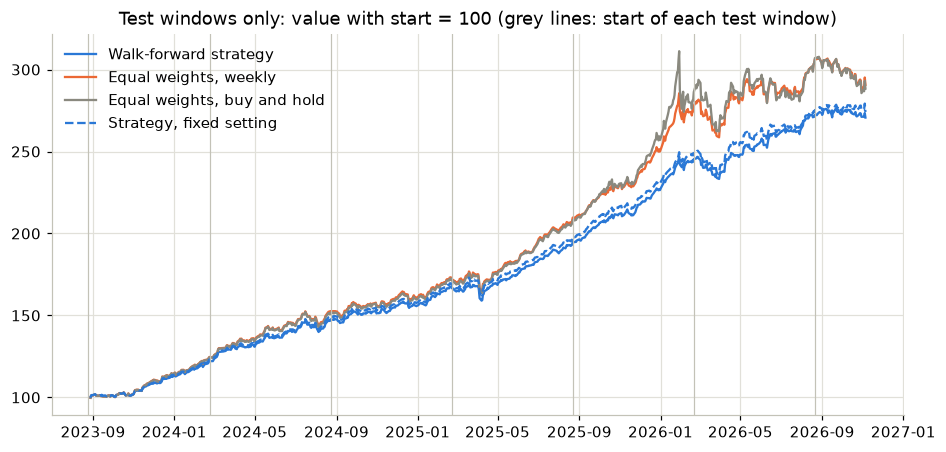

In [25]:
fig, ax = plt.subplots()
for name, result in tested.items():
    value = result["value"] / config.INITIAL_CAPITAL * 100  # start = 100
    style = "--" if name == "Strategy, fixed setting" else "-"
    label = "Walk-forward strategy" if name == "Strategy" else name
    ax.plot(value.index, value, linestyle=style, color=COLORS.get(name, BLUE), linewidth=1.5, label=label)
for fold in folds:
    ax.axvline(pd.Timestamp(fold["test"][0]), color="#c3c2b7", linewidth=0.8)  # start of each test window
ax.set_title("Test windows only: value with start = 100 (grey lines: start of each test window)")
ax.legend(loc="upper left", frameon=False)
plt.show()

**Reading the results.** Choosing the setting on the last 52 weeks did not help: the walk-forward strategy was behind the fixed setting in most windows, and the chosen setting changed often. The small differences between the settings in training do not continue in the next window, so they are mostly noise.

## 5. Parameter sensitivity

The strategy with other settings over the whole period. The first nine settings are the ones of the rolling validation; then one setting at a time is changed (the others stay as in `config.py`), and finally the costs.

In [26]:
sensitivity = []
for settings in validation.GRID + validation.ONE_AT_A_TIME:
    result = simulate.simulate(validation.strategy_weights(prices, settings).loc[strategy.index[0]:], data)
    sensitivity.append({"setting": validation.label(settings), **simulate.metrics(result)})
for name, commission, fx_cost in [("no costs", 0.0, 0.0), ("double costs", 2 * config.COMMISSION, 2 * config.FX_COST)]:
    result = simulate.simulate(strategy, data, commission=commission, fx_cost=fx_cost)
    sensitivity.append({"setting": name, **simulate.metrics(result)})

sensitivity = pd.DataFrame(sensitivity).set_index("setting")
sensitivity["Türkiye on average"] = sensitivity["average_share_pct"].map(lambda shares: shares["Türkiye"])
sensitivity[["total_return_pct", "volatility_pct", "sharpe", "max_drawdown_pct", "total_return_usd_pct",
             "turnover_per_year", "Türkiye on average"]]

,total_return_pct,volatility_pct,sharpe,max_drawdown_pct,total_return_usd_pct,turnover_per_year,Türkiye on average
setting,,,,,,,
"SMA 20/100, vol 21 days",337.98,8.31,4.29,-5.45,59.13,6.59,61.11
"SMA 20/100, vol 63 days",338.07,8.42,4.24,-5.54,59.16,4.92,61.95
"SMA 20/100, vol 126 days",344.55,8.45,4.26,-5.69,61.52,4.49,62.60
"SMA 50/150, vol 21 days",369.23,8.81,4.24,-6.23,70.48,5.09,60.20
"SMA 50/150, vol 63 days",372.09,8.88,4.23,-6.34,71.52,3.21,60.98
"SMA 50/150, vol 126 days",380.83,8.90,4.26,-6.28,74.70,2.73,61.63
"SMA 50/200, vol 21 days",369.23,8.96,4.17,-6.15,70.48,4.75,59.79
"SMA 50/200, vol 63 days",373.72,9.04,4.16,-6.22,72.11,2.86,60.48
"SMA 50/200, vol 126 days",383.86,9.04,4.22,-6.17,75.80,2.36,61.12


**Reading the results.** The trend and volatility windows change the result only a little, so it does not depend on one lucky setting. The volatility floor matters most, because it decides how much goes to the calm lira funds. Short windows trade much more. The costs take about 13 percentage points of total return over four years.

## 6. Weaknesses and possible improvements

The full discussion is in `docs/validation.md`, section 6. In short:

- **No higher return.** The strategy was calmer than the benchmarks but did not earn more.
- **High lira interest rates.** A lira money market fund alone earned about as much; a Sharpe ratio with a risk-free rate of 0 flatters every portfolio here.
- **The calm comes from the weighting.** 1 / volatility gives the calm lira funds a large weight (about 60% in Türkiye on average).
- **Choosing settings on the past did not work** in the rolling validation.
- **Short history from one period:** about four years of decisions, seven test windows, a lira that lost value quickly in all of them. Too few for a reliable statistical conclusion.
- **Slow trend signal and many small weekly trades.**
- **Selection bias:** the instruments were chosen in 2026.

**Ideas to test next:** compare with the money market fund and in US dollars; trade only when a weight is more than about two percentage points away from its target; keep idle money in the money market fund; add relative momentum and correlations (both are price signals); find longer Turkish fund histories. Phase 4 tests information other than prices.